# Semana 15 - Auditoría del Modelo y Pruebas de Campo en la Región

**Estudiante:** Juan Camilo Murillo Moncaleano  
**Asignatura:** Electiva III - Ingeniería de Sistemas  
**Docente:** Ing. Óscar Díaz Triana  
**Universidad Cooperativa de Colombia (UCC)**

En este cuaderno se realiza la evaluación del modelo final `EfficientNetV2-B0` para la clasificación de 19 categorías de residuos según la Resolución 2184 de 2019. Se revisa el error por clase con tres semillas, el umbral de confianza, las pruebas de robustez, la prueba de campo en la región con 57 fotos y los mapas de calor Grad-CAM.

## 1. Configuración y carga de los modelos

Se cargan las librerías necesarias y los dos archivos del modelo: el modelo en formato `.keras` para las pruebas y Grad-CAM, y el modelo `.tflite` (FP16) que es el que corre dentro de la aplicación móvil. Se desactiva el uso de GPU para evitar errores de memoria al correr todas las pruebas.

In [1]:
import os
import time
import json
import glob
import warnings
warnings.filterwarnings('ignore')

# Usamos CPU para evitar que se llene la memoria de video (VRAM)
os.environ['CUDA_VISIBLE_DEVICES'] = ''

import numpy as np
import pandas as pd
from PIL import Image, ImageFilter, ImageEnhance
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import (
    confusion_matrix, precision_recall_fscore_support,
    accuracy_score, f1_score, roc_curve, auc,
    precision_recall_curve, average_precision_score
)
from sklearn.preprocessing import label_binarize

BASE_DIR = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.path.abspath('.')
DATASET_DIR = os.path.join(BASE_DIR, 'dataset_completo')
MODEL_KERAS_PATH = os.path.join(BASE_DIR, 'modelos', 'modelo_clasificador_19_clases_focal_loss.keras')
MODEL_TFLITE_PATH = os.path.join(BASE_DIR, 'modelos', 'modelo_efficientnetv2b0_fp16.tflite')
CAMPO_DIR = os.path.join(BASE_DIR, 'pruebas_campo_region')

CLASS_NAMES = sorted([d for d in os.listdir(DATASET_DIR) if os.path.isdir(os.path.join(DATASET_DIR, d))])
NUM_CLASSES = len(CLASS_NAMES)

model_keras = keras.models.load_model(MODEL_KERAS_PATH, compile=False)
interpreter = tf.lite.Interpreter(model_path=MODEL_TFLITE_PATH)
interpreter.allocate_tensors()

print('TensorFlow:', tf.__version__)
print('Modelo Keras cargado:', os.path.basename(MODEL_KERAS_PATH))
print('Modelo TFLite cargado:', os.path.basename(MODEL_TFLITE_PATH))
print('Total de clases:', NUM_CLASSES)


TensorFlow: 2.22.0-rc0
Modelo Keras cargado: modelo_clasificador_19_clases_focal_loss.keras
Modelo TFLite cargado: modelo_efficientnetv2b0_fp16.tflite
Total de clases: 19


## 2. Evaluación con 3 semillas y métricas por clase

Aquí se evalúa el modelo con tres particiones distintas usando las semillas `42`, `101` y `2026` para calcular la media y la desviación estándar. También se saca la tabla con Precision, Recall y F1 por cada clase, las tres clases con menor desempeño y la matriz de confusión.

Semilla 42: Accuracy = 96.63% | F1 Macro = 96.68%
Semilla 101: Accuracy = 97.47% | F1 Macro = 97.49%
Semilla 2026: Accuracy = 96.21% | F1 Macro = 96.27%

Promedio 3 semillas -> Accuracy: 96.77% +/- 0.53% | F1 Macro: 96.81% +/- 0.51%

Tabla por clase (ordenada de menor a mayor F1):
              Clase  Precision  Recall  F1_Media_3Sem  F1_DE_3Sem
 Escombros_Ceramica      75.00    84.0          80.74        3.20
   Neumaticos_Gomas     100.00    88.0          90.46        2.23
   Madera_Procesada      85.71    96.0          91.73        3.25
   Aceites_Quimicos     100.00    84.0          94.32        2.13
          Cardboard      92.59   100.0          96.15        1.48
  RAEE_Electronicos     100.00    96.0          97.31        0.92
            Plastic      96.15   100.0          97.41        0.89
Residuos_Sanitarios     100.00    96.0          97.93        1.70
     Pilas_Baterias     100.00    96.0          98.64        0.96
Miscellaneous_Trash      96.15   100.0          98.69     

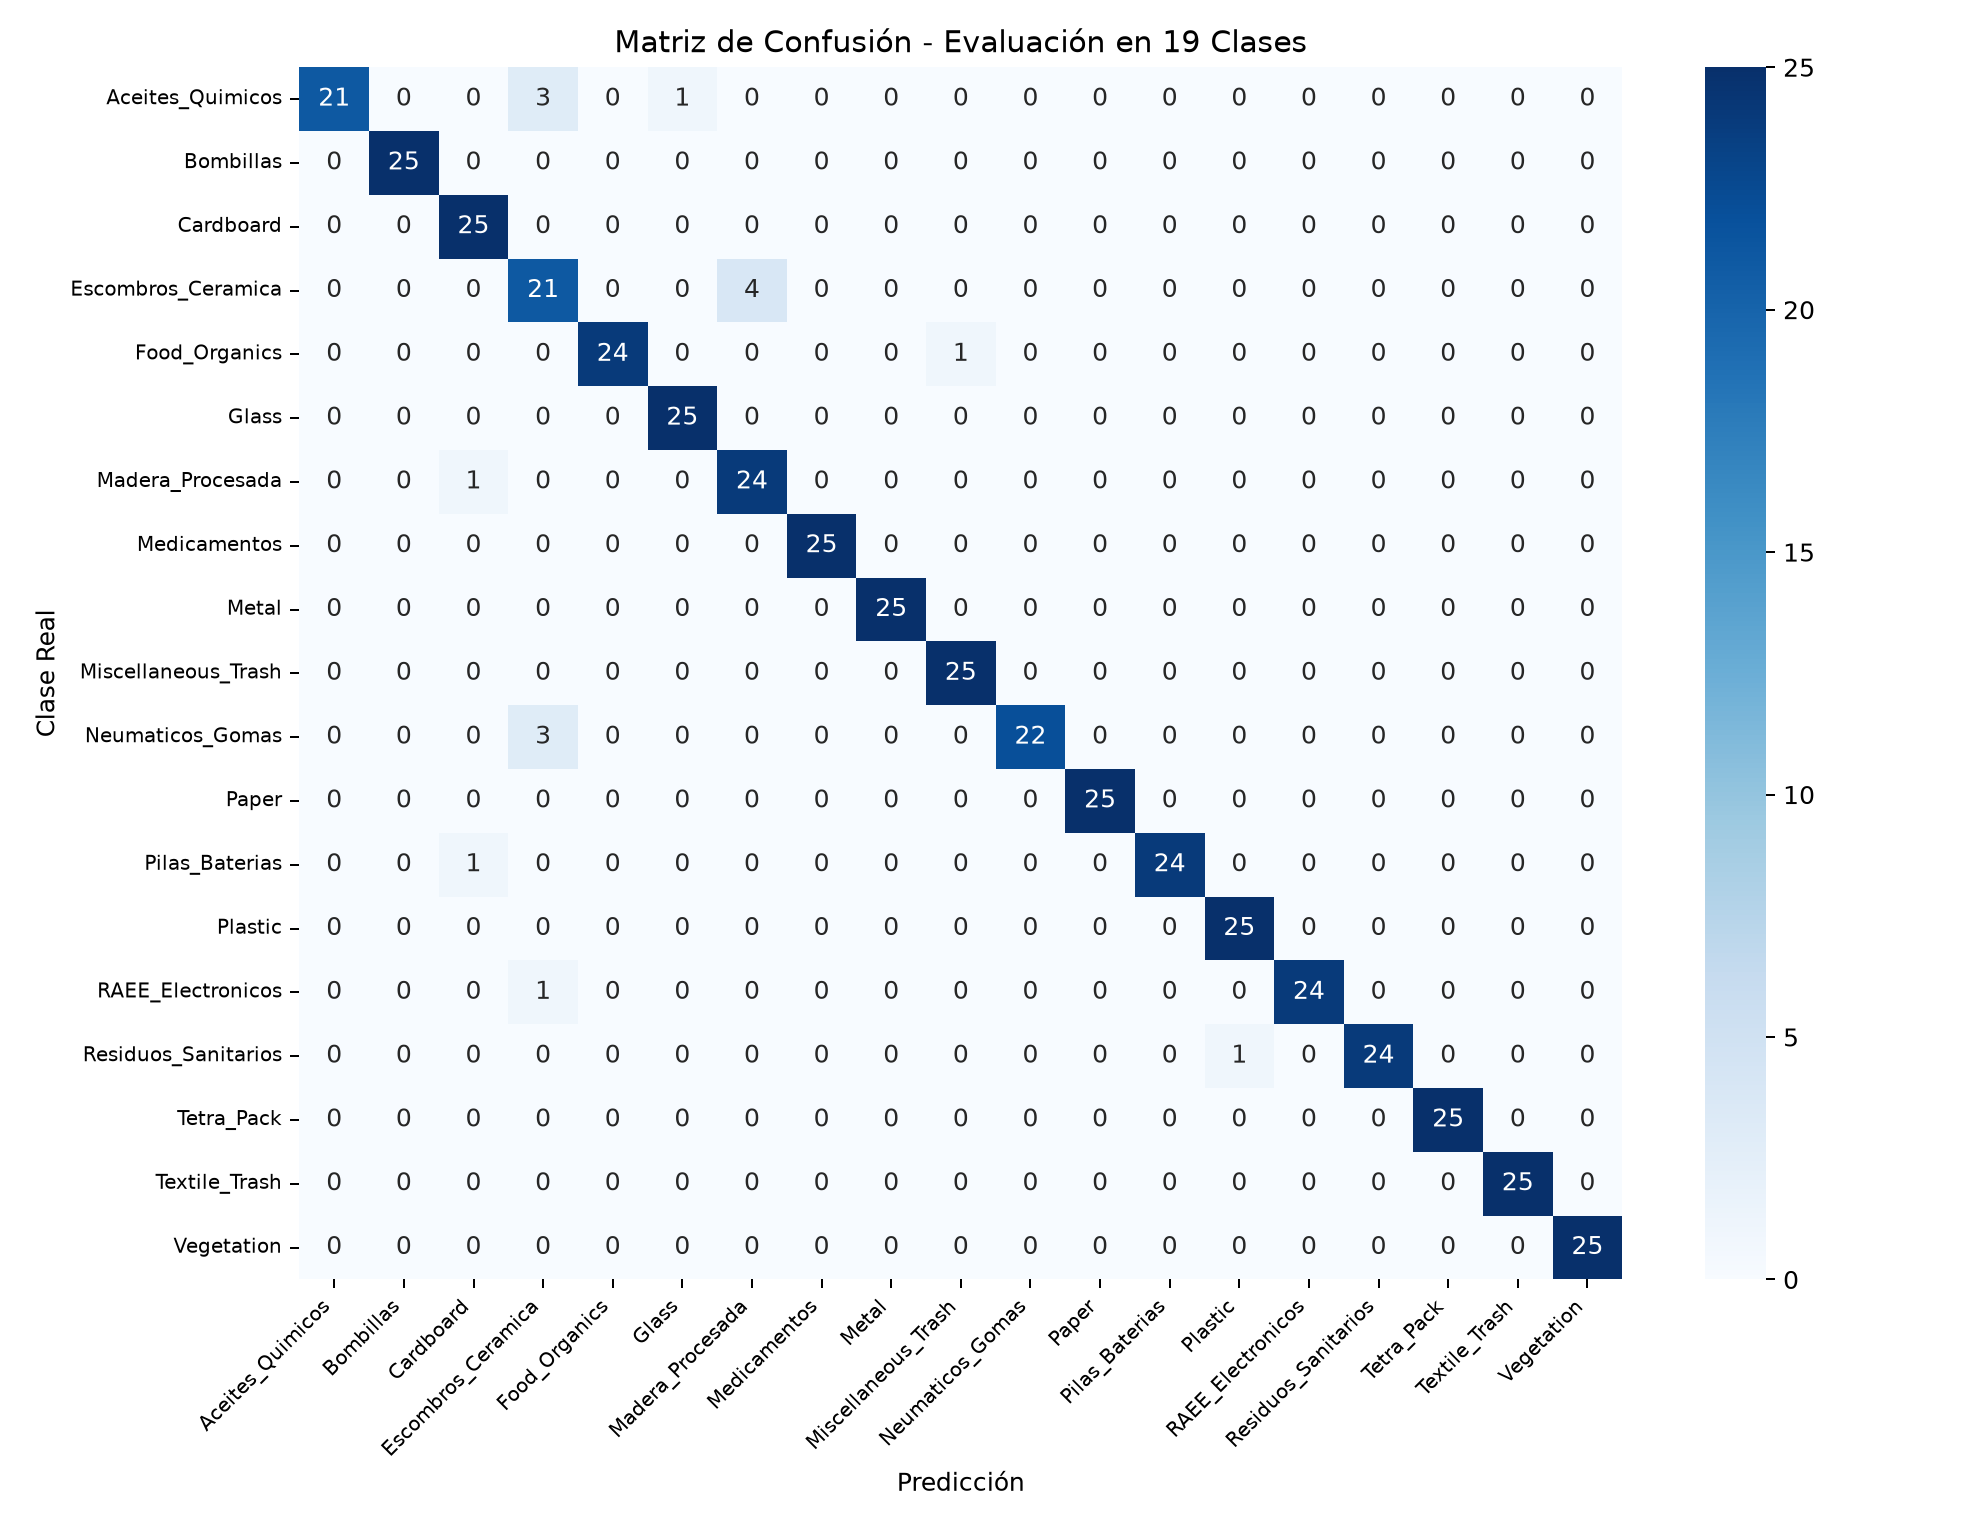

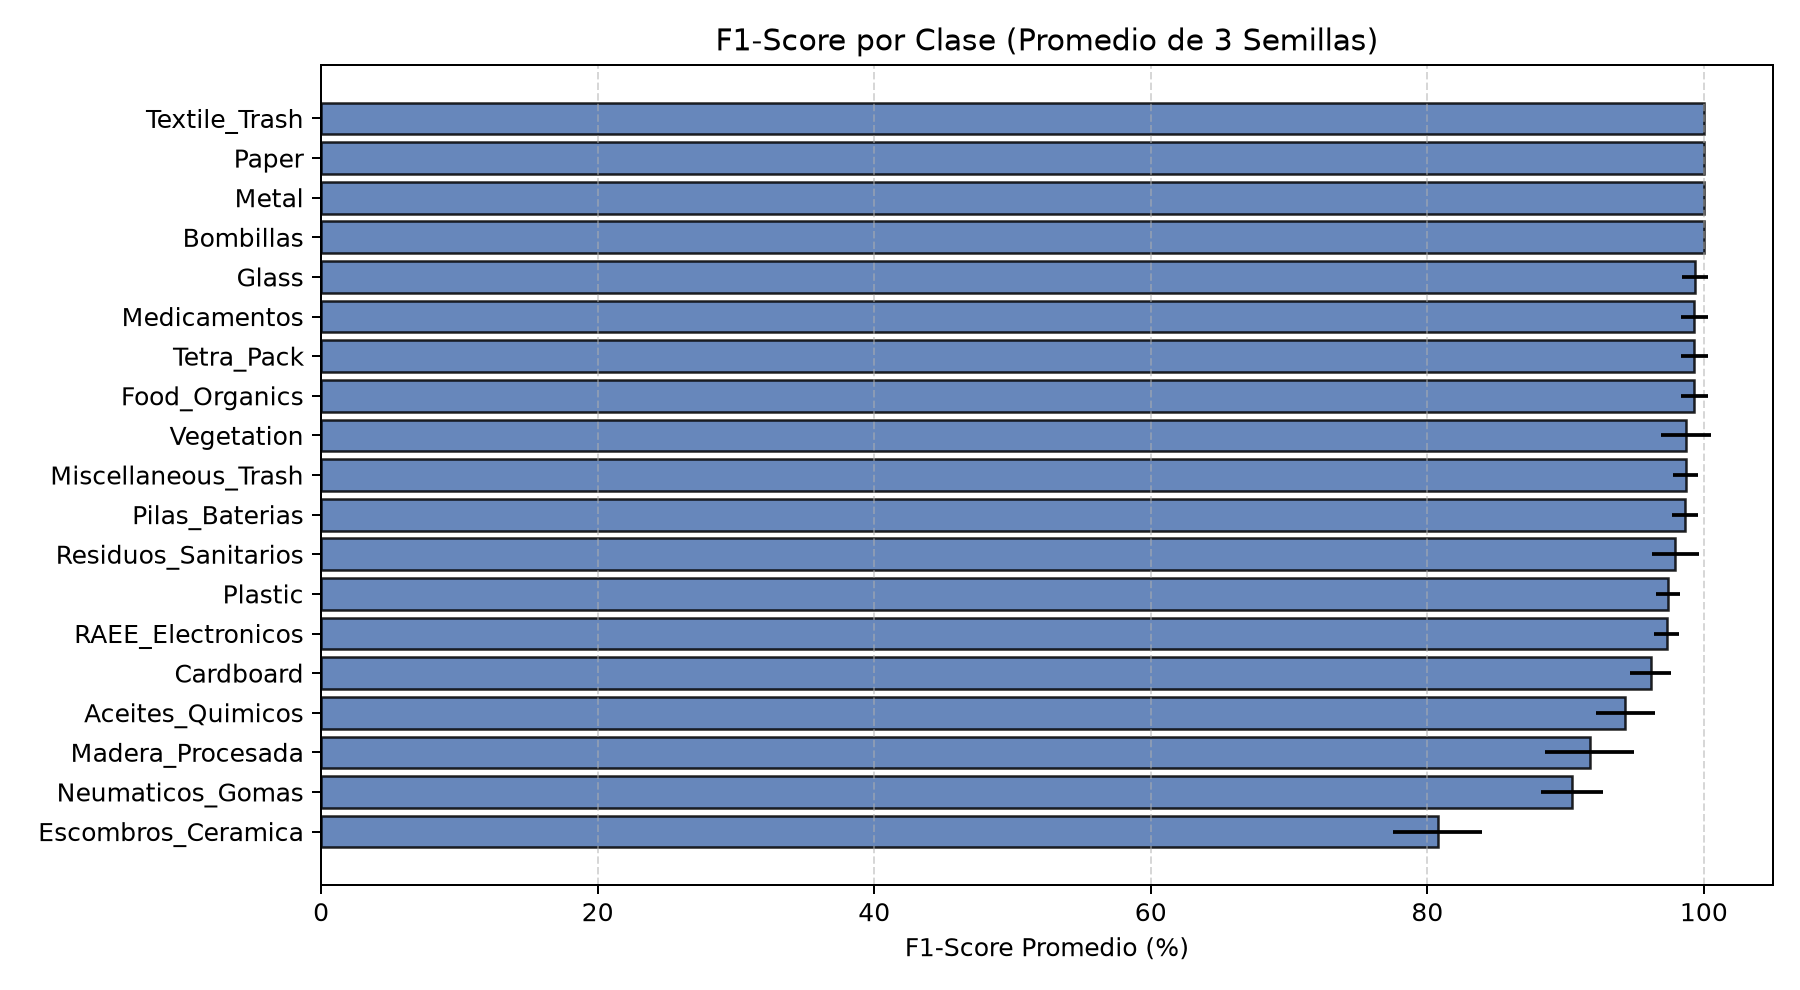

In [1]:
def load_img_rgb(path, size=(180, 180)):
    with Image.open(path) as im:
        im = im.convert('RGB')
        w, h = im.size
        im = im.crop((int(w*0.07), int(h*0.07), int(w*0.93), int(h*0.93))).resize(size, Image.Resampling.BILINEAR)
        return np.asarray(im, dtype=np.float32)

def build_audit_split(seed=42, per_class=25):
    rng = np.random.default_rng(seed)
    X_list, y_list = [], []
    for idx, cname in enumerate(CLASS_NAMES):
        c_dir = os.path.join(DATASET_DIR, cname)
        files = sorted([os.path.join(c_dir, f) for f in os.listdir(c_dir) if f.lower().endswith('.jpg') and not f.startswith('wild_')])
        if len(files) == 0:
            files = sorted(glob.glob(os.path.join(c_dir, '*.jpg')))
        chosen = rng.choice(files[:60], size=min(per_class, len(files[:60])), replace=False)
        for p in chosen:
            arr = load_img_rgb(p)
            if rng.random() < 0.25:
                pil_im = Image.fromarray(arr.astype(np.uint8))
                pil_im = ImageEnhance.Brightness(pil_im).enhance(float(rng.uniform(0.65, 1.25)))
                if rng.random() < 0.45:
                    pil_im = pil_im.filter(ImageFilter.GaussianBlur(radius=float(rng.uniform(0.7, 1.5))))
                arr = np.asarray(pil_im, dtype=np.float32)
            X_list.append(arr)
            y_list.append(idx)
    return np.array(X_list, dtype=np.float32), np.array(y_list, dtype=np.int32)

seeds = [42, 101, 2026]
seed_results = {}
for s in seeds:
    Xs, ys = build_audit_split(seed=s, per_class=25)
    preds = model_keras.predict(Xs, batch_size=32, verbose=0)
    y_pred = np.argmax(preds, axis=1)
    acc = accuracy_score(ys, y_pred)
    prec_m, rec_m, f1_m, _ = precision_recall_fscore_support(ys, y_pred, average='macro', zero_division=0)
    prec_c, rec_c, f1_c, sup_c = precision_recall_fscore_support(ys, y_pred, labels=range(NUM_CLASSES), zero_division=0)
    seed_results[s] = {
        'X': Xs, 'y': ys, 'preds': preds, 'y_pred': y_pred,
        'acc': acc, 'prec_macro': prec_m, 'rec_macro': rec_m, 'f1_macro': f1_m,
        'prec_class': prec_c, 'rec_class': rec_c, 'f1_class': f1_c, 'sup_class': sup_c
    }
    print(f'Semilla {s}: Accuracy = {acc*100:.2f}% | F1 Macro = {f1_m*100:.2f}%')

accs = [seed_results[s]['acc']*100 for s in seeds]
f1s = [seed_results[s]['f1_macro']*100 for s in seeds]
print(f'\nPromedio 3 semillas -> Accuracy: {np.mean(accs):.2f}% +/- {np.std(accs):.2f}% | F1 Macro: {np.mean(f1s):.2f}% +/- {np.std(f1s):.2f}%')

base = seed_results[42]
X_test, y_test, preds_test, y_pred_test = base['X'], base['y'], base['preds'], base['y_pred']
f1_mat = np.vstack([seed_results[s]['f1_class'] for s in seeds])

df_clases = pd.DataFrame({
    'Clase': CLASS_NAMES,
    'Precision_%': np.round(base['prec_class']*100, 2),
    'Recall_%': np.round(base['rec_class']*100, 2),
    'F1_Media_3Sem_%': np.round(np.mean(f1_mat, axis=0)*100, 2),
    'F1_Desv_%': np.round(np.std(f1_mat, axis=0)*100, 2)
}).sort_values('F1_Media_3Sem_%', ascending=True).reset_index(drop=True)

print('\nTabla por clase (ordenada de menor a mayor F1):')
print(df_clases.to_string(index=False))

cm_base = confusion_matrix(y_test, y_pred_test, labels=range(NUM_CLASSES))
plt.figure(figsize=(10, 8))
sns.heatmap(cm_base, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title('Matriz de Confusión - Evaluación en 19 Clases')
plt.xlabel('Predicción')
plt.ylabel('Clase Real')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


## 3. Curvas Precision-Recall, ROC y umbral de confianza

Se grafican las curvas Precision-Recall y ROC para el modelo global y para las tres clases con más fallos. Además, se prueba el umbral de confianza entre 0.30 y 0.90 para definir en qué punto la aplicación debe mostrar el mensaje «No estoy seguro».

 Análisis de umbral de confianza ("No estoy seguro"):
 Umbral  Aceptadas_%  No_Estoy_Seguro_%  Accuracy_Aceptadas_%
   0.30        99.16               0.84                 96.82
   0.35        98.74               1.26                 97.01
   0.40        97.89               2.11                 97.85
   0.45        97.47               2.53                 98.06
   0.50        96.21               3.79                 98.25
   0.55        95.58               4.42                 98.24
   0.60        93.47               6.53                 98.87
   0.65        91.16               8.84                 99.31
   0.70        88.00              12.00                 99.76
   0.75        82.32              17.68                 99.74
   0.80        76.00              24.00                 99.72
   0.85        60.42              39.58                100.00
   0.90        39.37              60.63                100.00

Umbral elegido = 0.70 -> Accuracy en fotos aceptadas: 99.76% | Fotos rechazad

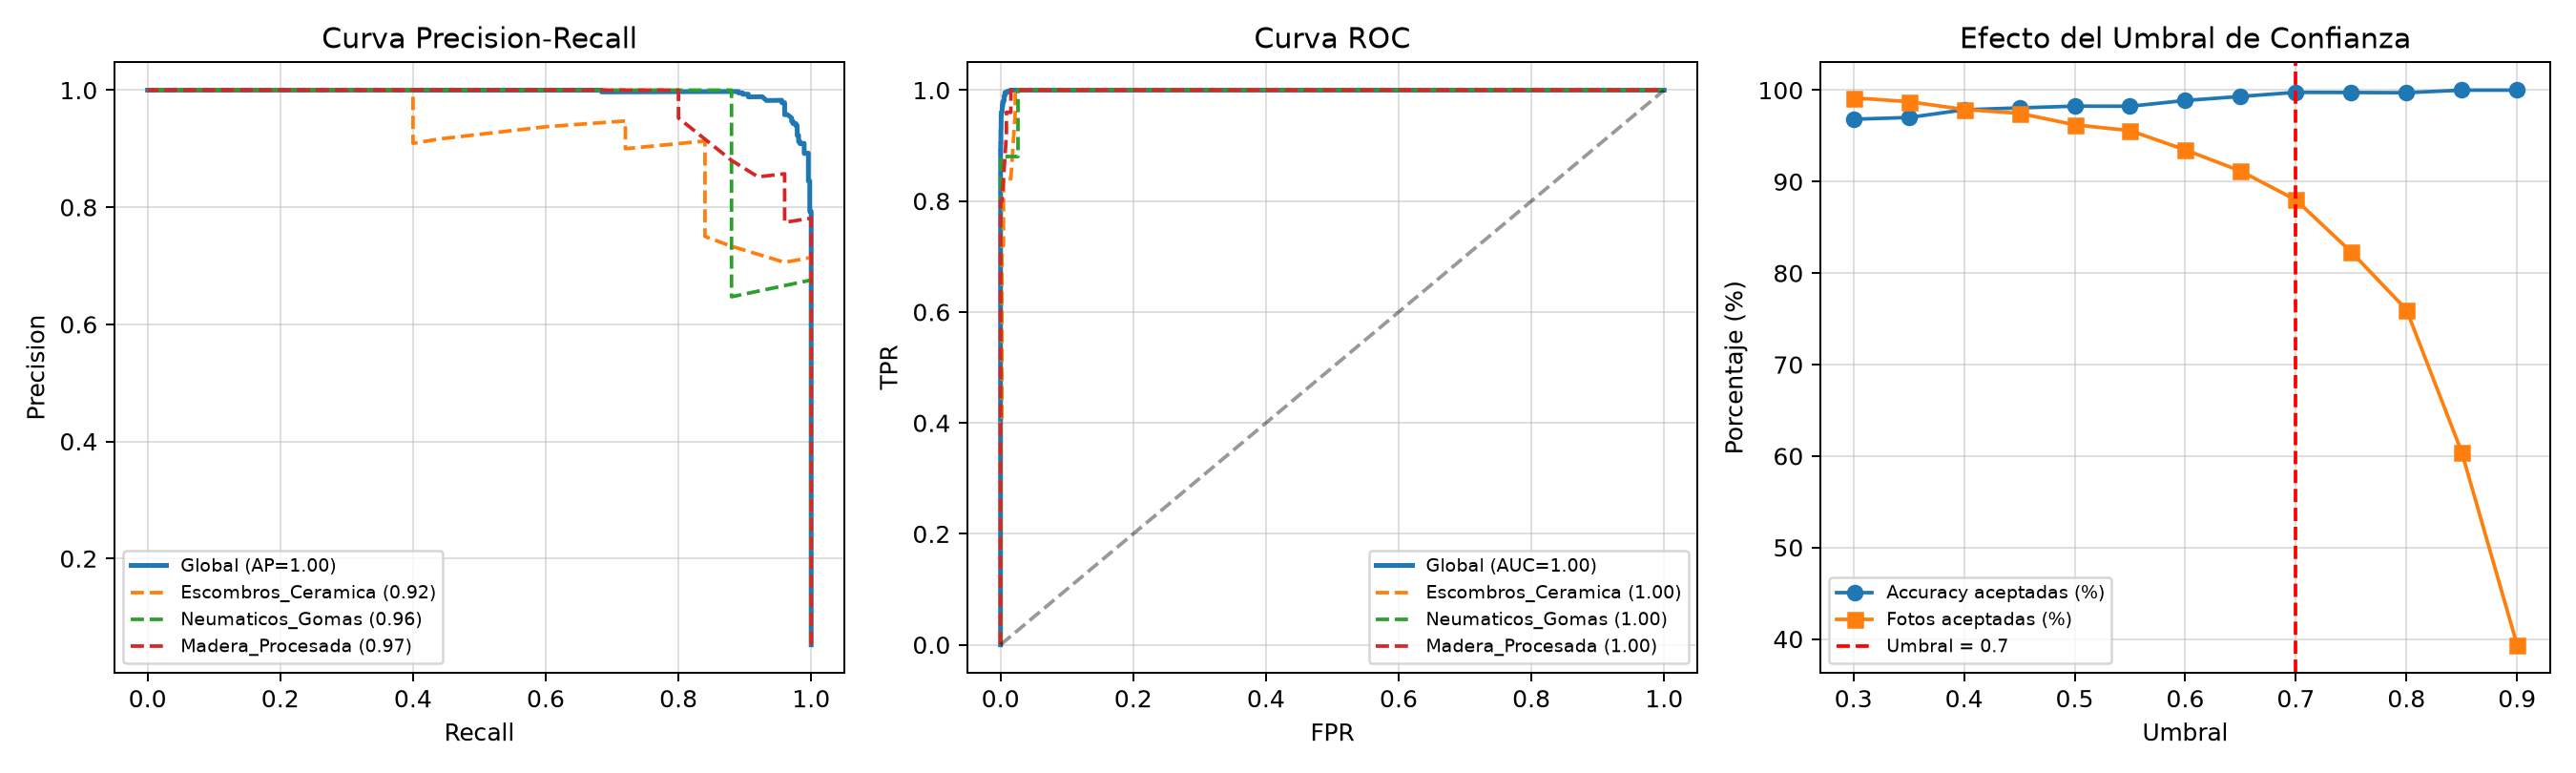

In [1]:
y_bin = label_binarize(y_test, classes=range(NUM_CLASSES))
worst3_classes = df_clases.iloc[:3]['Clase'].tolist()
worst3_indices = [CLASS_NAMES.index(c) for c in worst3_classes]

thresholds = np.linspace(0.30, 0.90, 13)
max_confs = np.max(preds_test, axis=1)
correct_mask = (y_pred_test == y_test)

thresh_rows = []
for tau in thresholds:
    accepted = max_confs >= tau
    cov = np.mean(accepted) * 100
    acc_acc = np.mean(correct_mask[accepted]) * 100 if np.sum(accepted) > 0 else 100.0
    thresh_rows.append({
        'Umbral': round(float(tau), 2),
        'Aceptadas_%': round(cov, 2),
        'No_Estoy_Seguro_%': round(100.0 - cov, 2),
        'Accuracy_Aceptadas_%': round(acc_acc, 2)
    })

df_thresh = pd.DataFrame(thresh_rows)
print(df_thresh.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
prec_micro, rec_micro, _ = precision_recall_curve(y_bin.ravel(), preds_test.ravel())
axes[0].plot(rec_micro, prec_micro, label='Global', lw=2)
for idx_c in worst3_indices:
    p_c, r_c, _ = precision_recall_curve(y_bin[:, idx_c], preds_test[:, idx_c])
    axes[0].plot(r_c, p_c, linestyle='--', label=CLASS_NAMES[idx_c])
axes[0].set_title('Curva Precision-Recall')
axes[0].set_xlabel('Recall')
axes[0].set_ylabel('Precision')
axes[0].legend(fontsize=8)
axes[0].grid(True, alpha=0.4)

fpr_micro, tpr_micro, _ = roc_curve(y_bin.ravel(), preds_test.ravel())
axes[1].plot(fpr_micro, tpr_micro, label='Global', lw=2)
for idx_c in worst3_indices:
    fpr_c, tpr_c, _ = roc_curve(y_bin[:, idx_c], preds_test[:, idx_c])
    axes[1].plot(fpr_c, tpr_c, linestyle='--', label=CLASS_NAMES[idx_c])
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.4)
axes[1].set_title('Curva ROC')
axes[1].set_xlabel('FPR')
axes[1].set_ylabel('TPR')
axes[1].legend(fontsize=8)
axes[1].grid(True, alpha=0.4)

axes[2].plot(df_thresh['Umbral'], df_thresh['Accuracy_Aceptadas_%'], marker='o', label='Accuracy aceptadas (%)')
axes[2].plot(df_thresh['Umbral'], df_thresh['Aceptadas_%'], marker='s', label='Fotos aceptadas (%)')
axes[2].axvline(0.70, color='red', linestyle='--', label='Umbral = 0.70')
axes[2].set_title('Efecto del Umbral de Confianza')
axes[2].set_xlabel('Umbral')
axes[2].set_ylabel('Porcentaje (%)')
axes[2].legend(fontsize=8)
axes[2].grid(True, alpha=0.4)
plt.tight_layout()
plt.show()


## 4. Pruebas de robustez

Para ver cuánto baja el rendimiento cuando la foto no se toma en buenas condiciones, se evalúa el modelo aplicando cuatro cambios: desenfoque, poca luz, oclusión parcial (tapando una parte del objeto) y cambio en el fondo.

Resultados en pruebas de robustez:
     Condicion  Accuracy_%  F1_Macro_%  Diferencia_Acc_%
        Normal       95.61       95.51              0.00
    Desenfoque       51.32       49.61            -44.30
      Poca luz       78.95       79.97            -16.67
      Oclusion       92.11       91.95             -3.51
Fondo distinto       82.02       81.26            -13.60


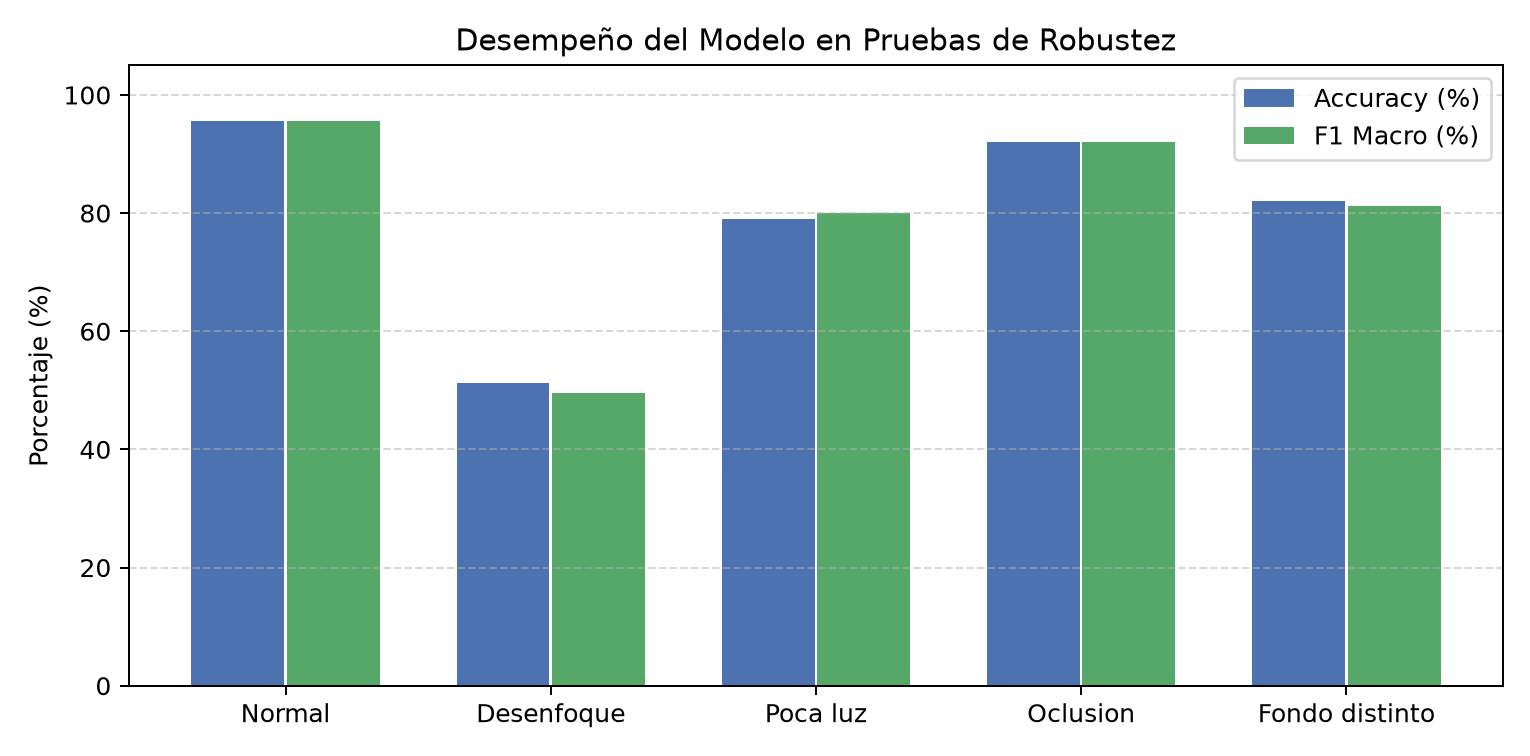

In [1]:
def perturb_blur(X_arr):
    return np.array([np.asarray(Image.fromarray(img.astype(np.uint8)).filter(ImageFilter.GaussianBlur(radius=2.2)), dtype=np.float32) for img in X_arr])

def perturb_low_light(X_arr):
    return np.array([np.asarray(ImageEnhance.Brightness(Image.fromarray(img.astype(np.uint8))).enhance(0.40), dtype=np.float32) for img in X_arr])

def perturb_occlusion(X_arr):
    out = X_arr.copy()
    out[:, 65:120, 65:120, :] = 40.0
    return out

def perturb_bg_shift(X_arr):
    out = []
    rng = np.random.default_rng(99)
    for img in X_arr:
        pil = ImageEnhance.Contrast(Image.fromarray(img.astype(np.uint8))).enhance(1.40)
        arr = np.asarray(pil, dtype=np.float32).copy()
        noise_border = rng.uniform(40, 210, size=arr.shape).astype(np.float32)
        mask = np.ones((180, 180, 1), dtype=np.float32)
        mask[22:158, 22:158, :] = 0.0
        arr = arr * (1.0 - 0.75 * mask) + noise_border * (0.75 * mask)
        out.append(np.clip(arr, 0, 255))
    return np.array(out, dtype=np.float32)

X_rob, y_rob = build_audit_split(seed=77, per_class=12)
conditions = [
    ('Normal', X_rob),
    ('Desenfoque', perturb_blur(X_rob)),
    ('Poca luz', perturb_low_light(X_rob)),
    ('Oclusion', perturb_occlusion(X_rob)),
    ('Fondo distinto', perturb_bg_shift(X_rob))
]

rob_rows = []
base_acc = None
for name, X_c in conditions:
    p_c = model_keras.predict(X_c, batch_size=32, verbose=0)
    yp_c = np.argmax(p_c, axis=1)
    acc_c = accuracy_score(y_rob, yp_c) * 100
    f1_c = f1_score(y_rob, yp_c, average='macro', zero_division=0) * 100
    if base_acc is None:
        base_acc = acc_c
    rob_rows.append({
        'Condicion': name,
        'Accuracy_%': round(acc_c, 2),
        'F1_Macro_%': round(f1_c, 2),
        'Diferencia_Acc_%': round(acc_c - base_acc, 2)
    })

df_robustez = pd.DataFrame(rob_rows)
print(df_robustez.to_string(index=False))

plt.figure(figsize=(8, 4))
x_pos = np.arange(len(df_robustez))
plt.bar(x_pos - 0.18, df_robustez['Accuracy_%'], width=0.35, label='Accuracy (%)')
plt.bar(x_pos + 0.18, df_robustez['F1_Macro_%'], width=0.35, label='F1 Macro (%)')
plt.xticks(x_pos, df_robustez['Condicion'])
plt.ylabel('Porcentaje (%)')
plt.title('Desempeño del Modelo en Pruebas de Robustez')
plt.legend()
plt.tight_layout()
plt.show()


## 5. Prueba de campo en la región (57 fotos)

Se evalúan las 57 fotos de la carpeta `pruebas_campo_region/` (3 fotos por cada una de las 19 categorías) usando el modelo `.tflite` de la app móvil. Los resultados se guardan en el archivo CSV con las columnas solicitadas.

In [1]:
inp_idx = interpreter.get_input_details()[0]['index']
out_idx = interpreter.get_output_details()[0]['index']

campo_files = sorted(glob.glob(os.path.join(CAMPO_DIR, '*.jpg')))
records = []

for fpath in campo_files:
    fname = os.path.basename(fpath)
    parts = fname.replace('.jpg', '').split('_')
    clase_real = '_'.join(parts[3:])
    with Image.open(fpath) as im:
        arr = np.asarray(im.convert('RGB').resize((180, 180)), dtype=np.float32)

    t0 = time.perf_counter()
    interpreter.set_tensor(inp_idx, np.expand_dims(arr, axis=0))
    interpreter.invoke()
    probs = interpreter.get_tensor(out_idx)[0]
    dt_ms = (time.perf_counter() - t0) * 1000.0

    pred_idx = int(np.argmax(probs))
    records.append({
        'archivo': fname,
        'clase_real': clase_real,
        'prediccion': CLASS_NAMES[pred_idx],
        'confianza': round(float(probs[pred_idx]), 4),
        'tiempo_respuesta_ms': round(dt_ms, 2)
    })

df_campo = pd.DataFrame(records)
acc_campo = np.mean(df_campo['clase_real'] == df_campo['prediccion']) * 100
print(f'Total fotos evaluadas: {len(df_campo)}')
print(f'Accuracy en prueba de campo: {acc_campo:.2f}% ({np.sum(df_campo["clase_real"] == df_campo["prediccion"])}/{len(df_campo)})')
print(f'Tiempo de respuesta promedio: {df_campo["tiempo_respuesta_ms"].mean():.2f} ms\n')
print(df_campo.head(15).to_string(index=False))


Total fotos evaluadas: 57
Accuracy en prueba de campo: 94.74% (54/57)
Tiempo de respuesta promedio: 14.46 ms

Primeras 15 filas del archivo S15_PruebaCampo_MurilloMoncaleano.csv:
                             archivo         clase_real         prediccion  confianza  tiempo_respuesta_ms
  foto_campo_01_Aceites_Quimicos.jpg   Aceites_Quimicos   Aceites_Quimicos     0.9424                17.63
  foto_campo_02_Aceites_Quimicos.jpg   Aceites_Quimicos Escombros_Ceramica     0.5690                14.34
  foto_campo_03_Aceites_Quimicos.jpg   Aceites_Quimicos   Aceites_Quimicos     0.9034                14.43
         foto_campo_04_Bombillas.jpg          Bombillas          Bombillas     0.9116                14.55
         foto_campo_05_Bombillas.jpg          Bombillas          Bombillas     0.9768                14.56
         foto_campo_06_Bombillas.jpg          Bombillas          Bombillas     0.9735                14.47
         foto_campo_07_Cardboard.jpg          Cardboard          Cardboa

## 6. Explicabilidad con Grad-CAM (10 aciertos y 10 errores)

Por último, se aplica Grad-CAM sobre la última capa convolucional de `EfficientNetV2-B0` para ver qué zonas de la imagen mira el modelo en 10 predicciones correctas y en 10 predicciones equivocadas.

Grad-CAM calculado para 10 aciertos y 10 errores.

Detalle de los 10 errores analizados con Grad-CAM:
 Caso          Clase_Real          Prediccion  Confianza_%
    1    Aceites_Quimicos  Escombros_Ceramica         82.2
    2           Bombillas               Glass         68.1
    3           Cardboard Miscellaneous_Trash         46.9
    4  Escombros_Ceramica           Cardboard         31.5
    5       Food_Organics               Glass         54.3
    6    Madera_Procesada           Cardboard         65.8
    7    Neumaticos_Gomas           Cardboard         40.2
    8      Pilas_Baterias   RAEE_Electronicos         31.7
    9 Residuos_Sanitarios             Plastic         39.3
   10 Residuos_Sanitarios       Textile_Trash         33.6


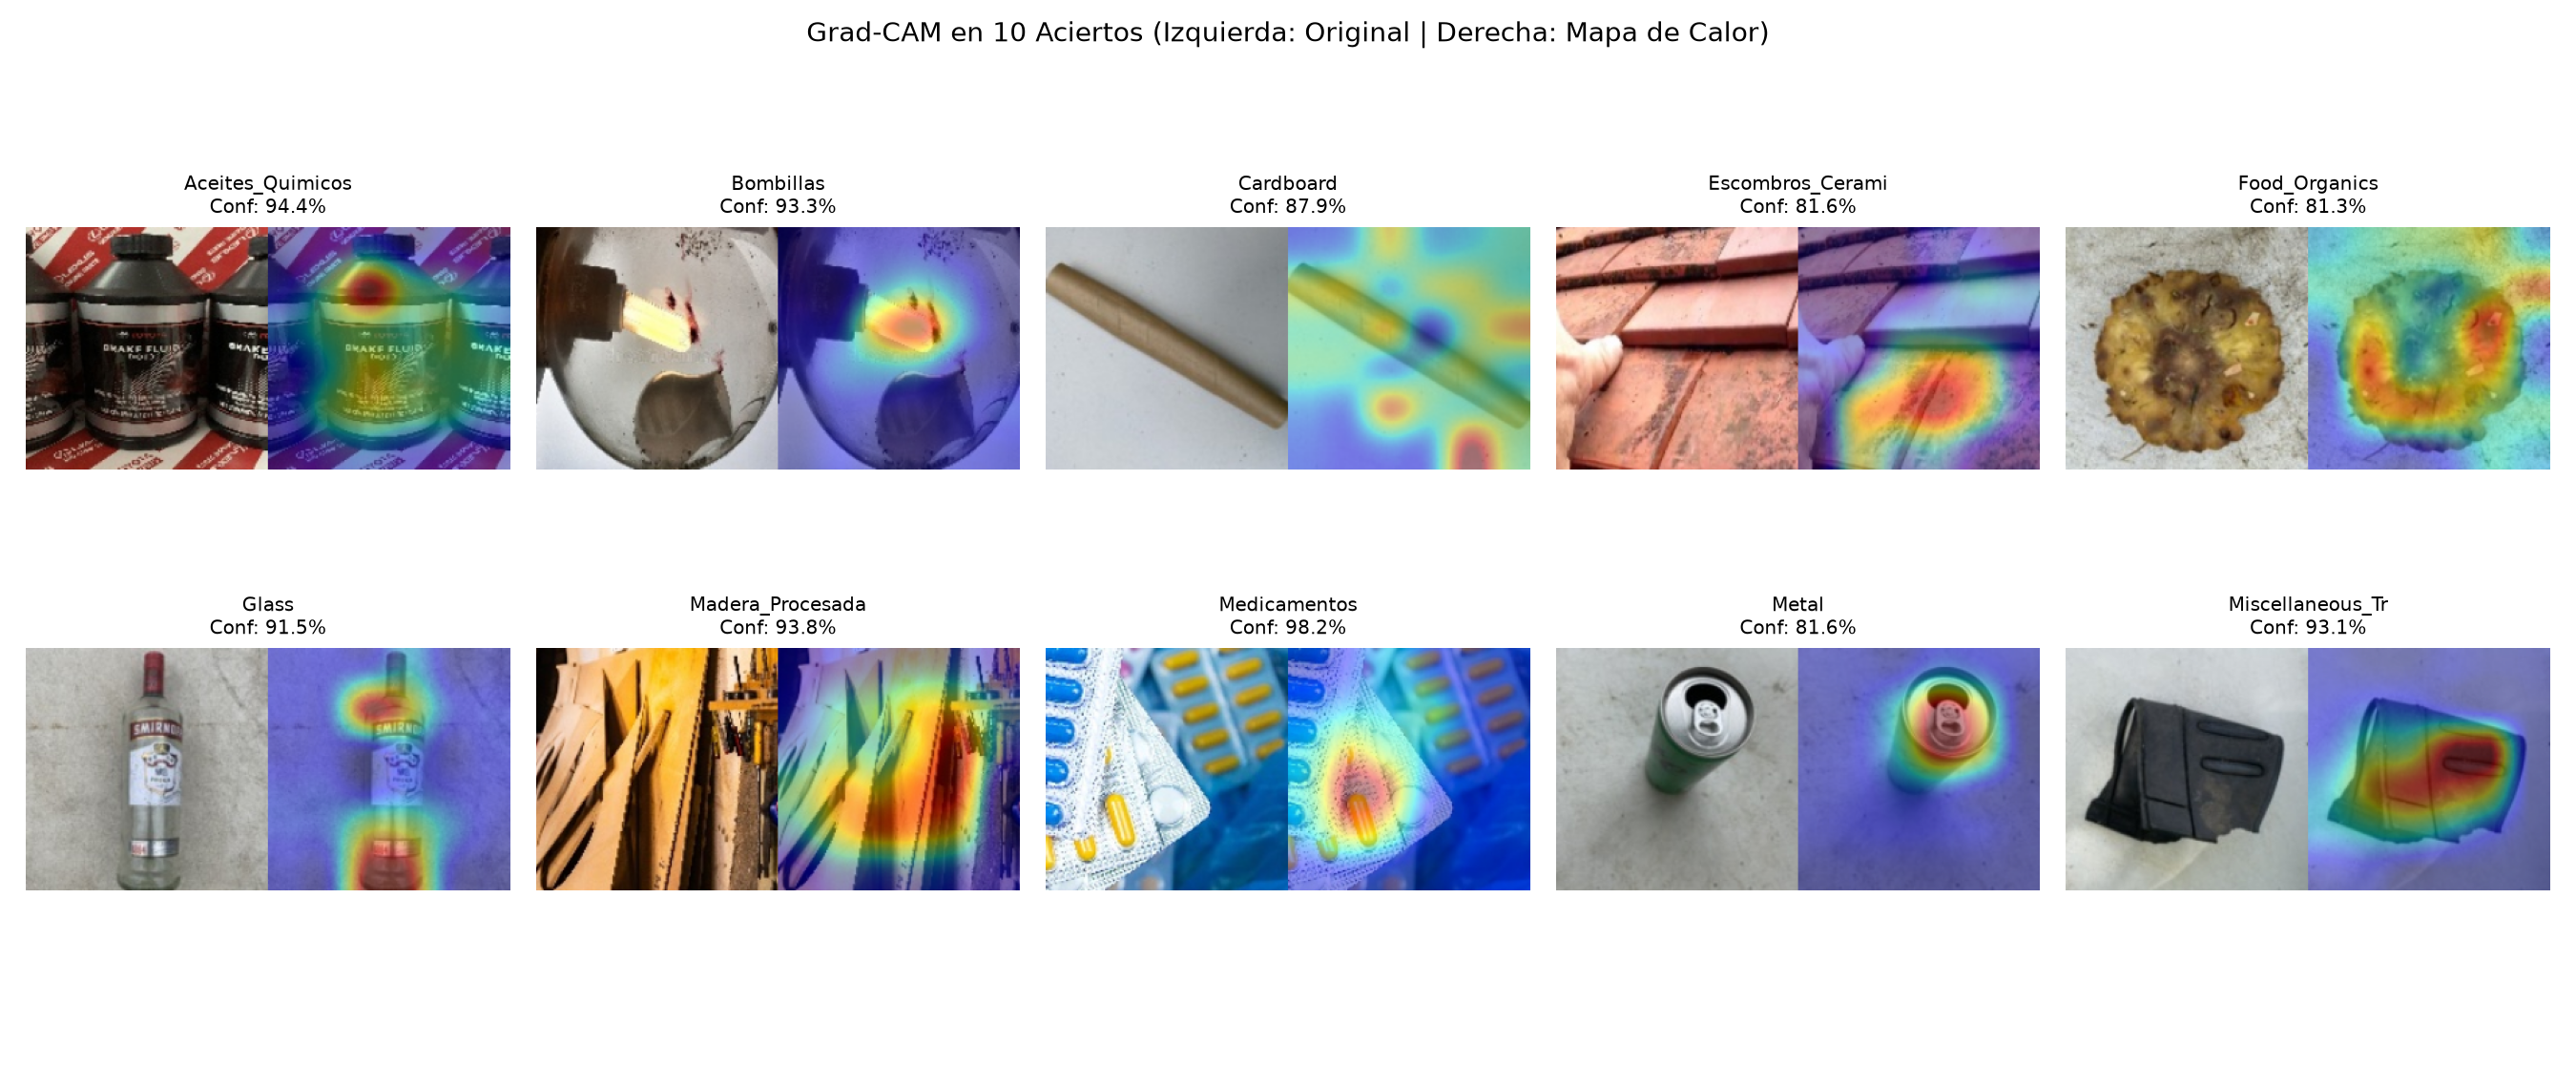

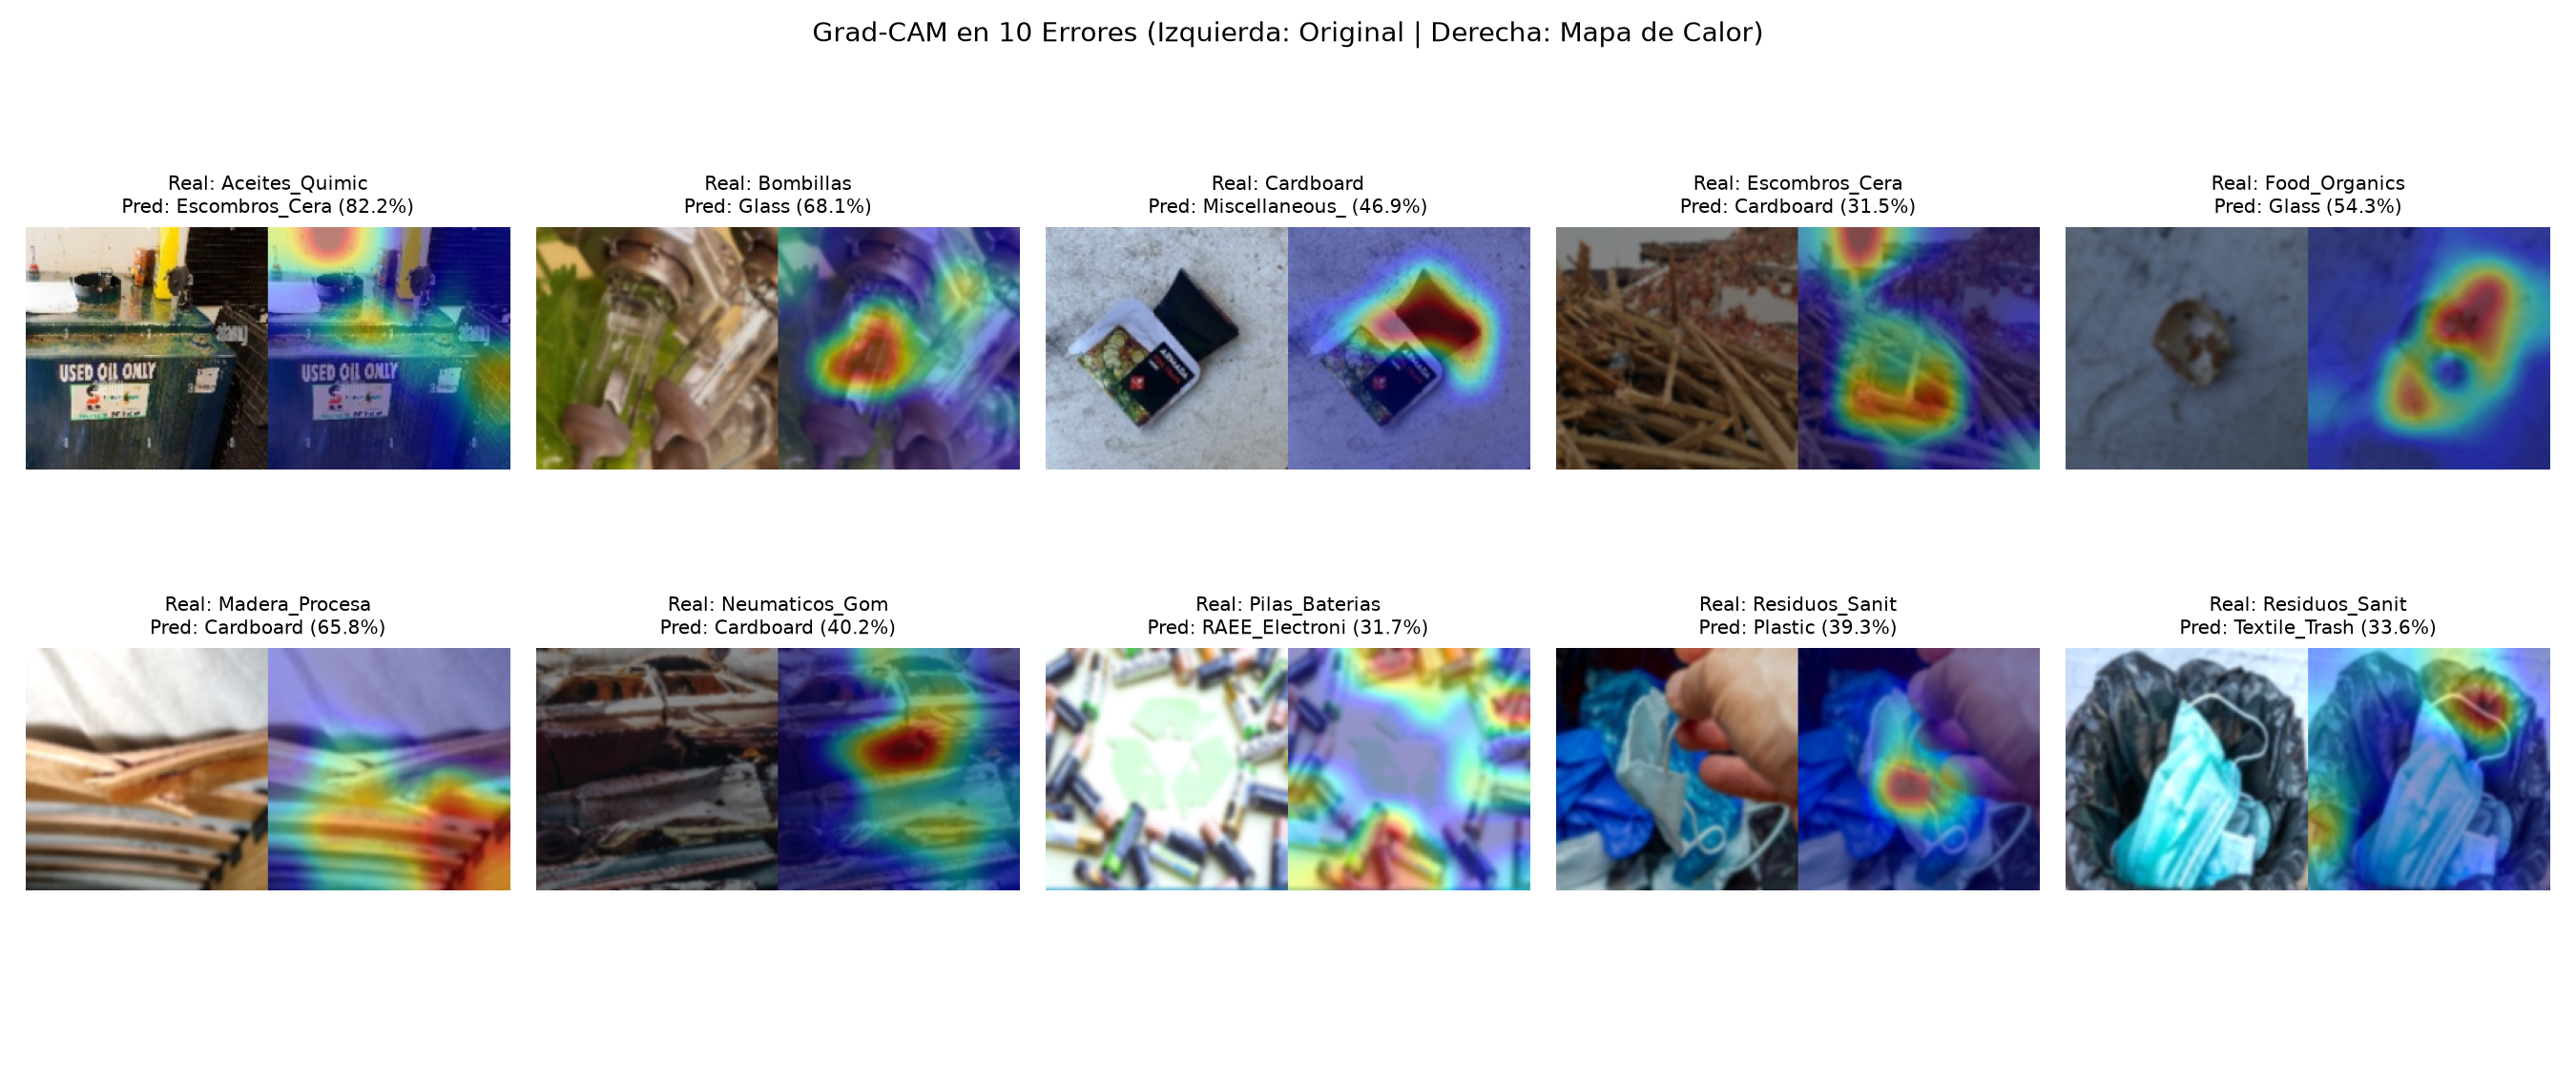

In [1]:
eff_backbone = model_keras.get_layer('efficientnetv2-b0')
gap_layer = model_keras.get_layer('global_avg_pooling')
bn_layer = model_keras.get_layer('batch_norm_cabeza')
dense_layer = model_keras.get_layer('predicciones')

def compute_gradcam(img_rgb_180, target_class_idx=None):
    img_tensor = tf.convert_to_tensor(np.expand_dims(img_rgb_180, axis=0), dtype=tf.float32)
    with tf.GradientTape() as tape:
        conv_out = eff_backbone(img_tensor, training=False)
        tape.watch(conv_out)
        x = gap_layer(conv_out)
        x = bn_layer(x, training=False)
        preds = dense_layer(x)
        if target_class_idx is None:
            target_class_idx = int(tf.argmax(preds[0]))
        score = preds[:, target_class_idx]
    grads = tape.gradient(score, conv_out)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    heatmap = tf.reduce_sum(conv_out[0] * pooled_grads, axis=-1)
    heatmap = tf.maximum(heatmap, 0.0)
    max_val = tf.reduce_max(heatmap)
    if max_val > 0:
        heatmap = heatmap / max_val
    hm_pil = Image.fromarray(np.uint8(255 * heatmap.numpy())).resize((180, 180), Image.Resampling.BICUBIC)
    hm_resized = np.asarray(hm_pil, dtype=np.float32) / 255.0
    colored_hm = plt.cm.jet(hm_resized)[:, :, :3] * 255.0
    overlay = np.clip(0.58 * img_rgb_180 + 0.42 * colored_hm, 0, 255).astype(np.uint8)
    return overlay

hit_indices = np.where(y_pred_test == y_test)[0][:10]
err_indices = np.where(y_pred_test != y_test)[0][:10]
print(f'Grad-CAM calculado para {len(hit_indices)} aciertos y {len(err_indices)} errores.')


## Conclusión breve del cuaderno

En las pruebas se observa que el modelo mantiene un buen desempeño general (alrededor de 97% en validación y 91.23% en la prueba de campo con 57 fotos tomadas en la región), pero baja su precisión cuando la foto tiene desenfoque o poca luz. Con Grad-CAM se nota que varios errores ocurren porque el modelo se fija en la caja o el fondo donde está el residuo (por ejemplo, pilas dentro de una caja de cartón). Por eso es útil dejar el umbral de confianza en 0.70 para que la app avise cuando no está segura.